# 23D2 — Dynamic World Window Sensitivity
## 60 / 90 / 120 / 180-day observation-coverage test before land-cover interpretation

### Why this notebook is needed

NB23D1 successfully:
- authenticated Google Earth Engine;
- matched all **126 / 126 exact FIRMS points**;
- extracted Dynamic World information.

However, the 60-day design failed the data-quality gate:
- overall reliable point coverage was low;
- the robust joint-high group had no points satisfying the minimum observation requirement.

Therefore, we **must not interpret** the existing Dynamic World land-cover differences yet.

This notebook tests whether the problem is simply an observation-window issue.

### Windows tested

- 60 days
- 90 days
- 120 days
- 180 days

### Fixed observation rule

A point is considered reliable when BOTH:
- recent-window mean valid-observation count ≥ 3
- reference-window mean valid-observation count ≥ 3

The minimum of 3 is **not changed** during sensitivity testing.

### Fixed selection rule — decided before looking at land-cover values

A window passes only if, for BOTH comparison groups:

> at least **80% of candidate cell-days** are reliable.

A cell-day is considered reliable if at least **50% of its exact FIRMS points**
pass the point-level reliability rule.

If multiple windows pass, select the **shortest** passing window.

If no tested window passes, Dynamic World change analysis is **not retained**
under this design.

### Important

Window selection uses **observation availability only**.

It does NOT use:
- tree decrease,
- crop increase,
- bare-ground increase,
- candidate/control effect size,
- or any result that could favor the research hypothesis.

This avoids cherry-picking.

In [10]:
# 1. Imports and locked settings

from pathlib import Path
import os
import json
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 300)

WINDOWS = [60, 90, 120, 180]

POINT_BUFFER_M = 200
MIN_VALID_OBSERVATIONS = 3

# Cell-day gate:
# at least 50% of exact FIRMS points in that cell-day must be reliable.
MIN_RELIABLE_POINT_SHARE_PER_CELL_DAY = 0.50

# Window gate:
# both research groups must have at least 80% reliable cell-days.
MIN_GROUP_CELL_DAY_COVERAGE = 0.80

MANUAL_EE_PROJECT = "skripsi-karhut"

In [11]:
# 2. Resolve project root and exact FIRMS input

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    p = (
        root
        / "model_results"
        / "external_context_integration"
        / "t2"
        / "exports"
        / "exact_firms_point_context.csv"
    )

    if p.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate NB23D exact_firms_point_context.csv. "
        "Run NB23D first."
    )

NB23D_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "external_context_integration"
    / "t2"
)

POINT_PATH = (
    NB23D_DIR
    / "exports"
    / "exact_firms_point_context.csv"
)

CACHE_DIR = NB23D_DIR / "cache"
EXPORT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "dynamic_world_window_sensitivity"
    / "t2"
    / "exports"
)
FIGURE_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "dynamic_world_window_sensitivity"
    / "t2"
    / "figures"
)

for p in [CACHE_DIR, EXPORT_DIR, FIGURE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

CANONICAL_CACHE_PATH = (
    CACHE_DIR
    / "dynamic_world_point_context.csv"
)

SELECTED_CACHE_PATH = (
    CACHE_DIR
    / "dynamic_world_point_context_selected_window.csv"
)

COVERAGE_CACHE_PATH = (
    CACHE_DIR
    / "dynamic_world_window_coverage_points.csv"
)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("POINT_PATH:", POINT_PATH)
print("Canonical NB23D cache:", CANONICAL_CACHE_PATH)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
POINT_PATH: c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2\exports\exact_firms_point_context.csv
Canonical NB23D cache: c:\Users\Asus\Documents\skripsi-karhut\model_results\external_context_integration\t2\cache\dynamic_world_point_context.csv


In [12]:
# 3. Load exact FIRMS points

points = pd.read_csv(
    POINT_PATH,
    parse_dates=["event_date"],
)

required = {
    "firms_point_id",
    "candidate_event_id",
    "context_group",
    "event_date",
    "firms_lat",
    "firms_lon",
}

missing = sorted(required - set(points.columns))

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

points = (
    points[
        [
            "firms_point_id",
            "candidate_event_id",
            "context_group",
            "event_date",
            "firms_lat",
            "firms_lon",
        ]
    ]
    .drop_duplicates("firms_point_id")
    .sort_values(
        [
            "event_date",
            "candidate_event_id",
            "firms_point_id",
        ]
    )
    .reset_index(drop=True)
)

print("Exact FIRMS points:", len(points))
print("Cell-days:", points["candidate_event_id"].nunique())
print()
print("Points by group:")
display(
    points["context_group"]
    .value_counts()
    .rename("points")
    .to_frame()
)

print("Cell-days by group:")
display(
    points[
        ["candidate_event_id", "context_group"]
    ]
    .drop_duplicates()
    ["context_group"]
    .value_counts()
    .rename("cell_days")
    .to_frame()
)

Exact FIRMS points: 126
Cell-days: 59

Points by group:


,points
context_group,
History-novel / env-plausible,111
Robust joint-high,15


Cell-days by group:


,cell_days
context_group,
History-novel / env-plausible,53
Robust joint-high,6


# PART A — Earth Engine connection

This notebook first tries your existing Earth Engine credentials.

If they are unavailable:
1. it tries `auth_mode="localhost"` for local Jupyter;
2. if needed, it falls back to `auth_mode="notebook"`.

Do not share authorization codes or tokens.

In [13]:
# 4. Import and initialize Earth Engine

try:
    import ee
except ImportError as exc:
    raise ImportError(
        "earthengine-api is not installed. Run:\n"
        "pip install -U earthengine-api\n"
        "Then restart the Jupyter kernel."
    ) from exc

EE_PROJECT = os.getenv(
    "EE_PROJECT",
    "",
).strip()

if not EE_PROJECT:
    EE_PROJECT = MANUAL_EE_PROJECT.strip()

if not EE_PROJECT:
    raise ValueError(
        "EE_PROJECT is empty. Fill MANUAL_EE_PROJECT."
    )

print("EE_PROJECT:", EE_PROJECT)


def initialize_earth_engine(project_id):
    try:
        ee.Initialize(project=project_id)
        print("Earth Engine initialized using existing credentials.")
        return

    except Exception:
        print("Existing credentials unavailable. Trying localhost authentication.")

    try:
        ee.Authenticate(
            auth_mode="localhost",
            force=True,
        )
        ee.Initialize(project=project_id)
        print("Earth Engine authenticated with localhost mode.")
        return

    except Exception as exc:
        print("Localhost authentication failed:", repr(exc))
        print("Trying notebook authentication.")

    ee.Authenticate(
        auth_mode="notebook",
        force=True,
    )
    ee.Initialize(project=project_id)
    print("Earth Engine authenticated with notebook mode.")


initialize_earth_engine(EE_PROJECT)

assert ee.Number(1).getInfo() == 1

print("Earth Engine connection: OK")

EE_PROJECT: skripsi-karhut


Earth Engine initialized using existing credentials.
Earth Engine connection: OK


# PART B — Coverage-only sensitivity extraction

This is intentionally separate from land-cover analysis.

For each event date we create, for all four windows:
- recent Dynamic World observation-count band;
- same-season previous-year reference observation-count band.

Then we sample those count bands around the exact FIRMS locations.

This is substantially cheaper and methodologically cleaner than repeatedly extracting
all land-cover probability bands for every candidate window.

In [14]:
# 5. Build all coverage bands for one event date

def build_coverage_stack(event_date):
    event_date = pd.Timestamp(event_date)

    stack = None
    metadata = {}

    for window in WINDOWS:
        recent_start = (
            event_date
            - pd.Timedelta(days=window)
        )
        recent_end = event_date

        ref_start = (
            recent_start
            - pd.DateOffset(years=1)
        )
        ref_end = (
            recent_end
            - pd.DateOffset(years=1)
        )

        recent_col = (
            ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
            .filterDate(
                str(recent_start.date()),
                str(recent_end.date()),
            )
        )

        ref_col = (
            ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
            .filterDate(
                str(ref_start.date()),
                str(ref_end.date()),
            )
        )

        recent_count = (
            recent_col
            .select(["trees"])
            .count()
            .rename(
                [f"obs_recent_{window}d"]
            )
        )

        ref_count = (
            ref_col
            .select(["trees"])
            .count()
            .rename(
                [f"obs_ref_{window}d"]
            )
        )

        pair = recent_count.addBands(
            ref_count
        )

        stack = (
            pair
            if stack is None
            else stack.addBands(pair)
        )

        metadata[f"recent_collection_size_{window}d"] = int(
            recent_col.size().getInfo()
        )
        metadata[f"ref_collection_size_{window}d"] = int(
            ref_col.size().getInfo()
        )

    return stack, metadata

In [15]:
# 6. Extract coverage for one event date

def extract_coverage_for_date(points_for_date, event_date):
    stack, metadata = build_coverage_stack(
        event_date
    )

    features = []

    for row in points_for_date.itertuples(index=False):
        geometry = (
            ee.Geometry.Point(
                [
                    float(row.firms_lon),
                    float(row.firms_lat),
                ]
            )
            .buffer(POINT_BUFFER_M)
        )

        features.append(
            ee.Feature(
                geometry,
                {
                    "firms_point_id": row.firms_point_id,
                    "candidate_event_id": row.candidate_event_id,
                    "context_group": row.context_group,
                    "event_date": str(
                        pd.Timestamp(
                            row.event_date
                        ).date()
                    ),
                },
            )
        )

    fc = ee.FeatureCollection(features)

    reduced = stack.reduceRegions(
        collection=fc,
        reducer=ee.Reducer.mean(),
        scale=10,
        tileScale=4,
    )

    info = reduced.getInfo()

    rows = [
        f.get("properties", {})
        for f in info.get(
            "features",
            [],
        )
    ]

    result = pd.DataFrame(rows)

    for key, value in metadata.items():
        result[key] = value

    return result

In [9]:
# 7. Run coverage extraction or load existing coverage cache

if COVERAGE_CACHE_PATH.exists():
    coverage_points = pd.read_csv(
        COVERAGE_CACHE_PATH,
        parse_dates=["event_date"],
    )

    print(
        "Loaded existing coverage cache:",
        COVERAGE_CACHE_PATH,
    )

else:
    parts = []

    for event_date, subset in points.groupby(
        "event_date"
    ):
        event_date = pd.Timestamp(event_date)

        print(
            "Coverage extraction:",
            event_date.date(),
            "| points:",
            len(subset),
        )

        part = extract_coverage_for_date(
            subset,
            event_date,
        )

        if len(part):
            parts.append(part)

    if not parts:
        raise RuntimeError(
            "Coverage extraction returned zero rows."
        )

    coverage_points = pd.concat(
        parts,
        ignore_index=True,
    )

    coverage_points["event_date"] = pd.to_datetime(
        coverage_points["event_date"]
    )

    coverage_points.to_csv(
        COVERAGE_CACHE_PATH,
        index=False,
    )

    print()
    print(
        "Saved coverage cache:",
        COVERAGE_CACHE_PATH,
    )

print("Coverage rows:", len(coverage_points))

Coverage extraction: 2026-08-06 | points: 12
Coverage extraction: 2026-08-07 | points: 6
Coverage extraction: 2026-08-08 | points: 12
Coverage extraction: 2026-08-09 | points: 2
Coverage extraction: 2026-08-10 | points: 8
Coverage extraction: 2026-08-11 | points: 2
Coverage extraction: 2026-08-12 | points: 3
Coverage extraction: 2026-08-14 | points: 4
Coverage extraction: 2026-08-15 | points: 7
Coverage extraction: 2026-08-16 | points: 6
Coverage extraction: 2026-08-17 | points: 19
Coverage extraction: 2026-08-18 | points: 10
Coverage extraction: 2026-08-19 | points: 3
Coverage extraction: 2026-08-22 | points: 3
Coverage extraction: 2026-08-23 | points: 2
Coverage extraction: 2026-08-25 | points: 1
Coverage extraction: 2026-08-26 | points: 11
Coverage extraction: 2026-08-27 | points: 3
Coverage extraction: 2026-08-28 | points: 4
Coverage extraction: 2026-08-29 | points: 6
Coverage extraction: 2026-08-31 | points: 2

Saved coverage cache: c:\Users\Asus\Documents\skripsi-karhut\model_res

In [16]:
# 8. Validate one-to-one extraction

input_ids = set(
    points["firms_point_id"]
)

output_ids = set(
    coverage_points["firms_point_id"]
)

missing_ids = sorted(
    input_ids - output_ids
)

extra_ids = sorted(
    output_ids - input_ids
)

print("Input point IDs :", len(input_ids))
print("Output point IDs:", len(output_ids))
print("Missing IDs     :", len(missing_ids))
print("Unexpected IDs  :", len(extra_ids))

if missing_ids or extra_ids:
    raise RuntimeError(
        "Coverage extraction point IDs do not match exact FIRMS input."
    )

Input point IDs : 126
Output point IDs: 126
Missing IDs     : 0
Unexpected IDs  : 0


# PART C — Reliability at point and cell-day level

## Point level

For window `W`:

`point_reliable_W = recent_obs >= 3 AND reference_obs >= 3`

## Cell-day level

A cell-day is reliable if at least 50% of its exact FIRMS detections are point-reliable.

Why aggregate to cell-day?

Because NB23C/NB23D candidates are **cell-day events**, while multiple FIRMS rows inside one
cell-day are repeated spatial detections and should not automatically give that event more weight.

In [17]:
# 9. Derive reliability flags

for window in WINDOWS:
    recent_col = f"obs_recent_{window}d"
    ref_col = f"obs_ref_{window}d"

    coverage_points[recent_col] = pd.to_numeric(
        coverage_points[recent_col],
        errors="coerce",
    )

    coverage_points[ref_col] = pd.to_numeric(
        coverage_points[ref_col],
        errors="coerce",
    )

    coverage_points[
        f"point_reliable_{window}d"
    ] = (
        coverage_points[recent_col]
        .ge(MIN_VALID_OBSERVATIONS)
        &
        coverage_points[ref_col]
        .ge(MIN_VALID_OBSERVATIONS)
    )

print("Reliability flags created.")

Reliability flags created.


In [18]:
# 10. Point-level coverage summary

point_rows = []

for window in WINDOWS:
    flag = f"point_reliable_{window}d"

    for group, subset in coverage_points.groupby(
        "context_group"
    ):
        point_rows.append({
            "window_days": window,
            "context_group": group,
            "points": len(subset),
            "reliable_points": int(
                subset[flag].sum()
            ),
            "point_reliable_share": float(
                subset[flag].mean()
            ),
            "recent_obs_median": float(
                subset[
                    f"obs_recent_{window}d"
                ].median()
            ),
            "reference_obs_median": float(
                subset[
                    f"obs_ref_{window}d"
                ].median()
            ),
        })

point_coverage = pd.DataFrame(
    point_rows
)

display(point_coverage)

,window_days,context_group,points,reliable_points,point_reliable_share,recent_obs_median,reference_obs_median
0,60,History-novel / env-plausible,111,35,0.315315,4.066470,2.208986
1,60,Robust joint-high,15,0,0.000000,1.087108,1.000000
2,90,History-novel / env-plausible,111,41,0.369369,4.232699,3.000000
3,90,Robust joint-high,15,0,0.000000,1.188605,1.000000
4,120,History-novel / env-plausible,111,61,0.549550,5.999471,3.597529
5,120,Robust joint-high,15,0,0.000000,2.165986,1.941572
6,180,History-novel / env-plausible,111,65,0.585586,6.679566,3.961752
7,180,Robust joint-high,15,0,0.000000,2.174215,1.048738


In [19]:
# 11. Cell-day reliability table

cell_day_parts = []

for window in WINDOWS:
    flag = f"point_reliable_{window}d"

    part = (
        coverage_points
        .groupby(
            [
                "candidate_event_id",
                "context_group",
                "event_date",
            ],
            as_index=False,
        )
        .agg(
            exact_points=(
                "firms_point_id",
                "size",
            ),
            reliable_points=(
                flag,
                "sum",
            ),
            reliable_point_share=(
                flag,
                "mean",
            ),
            recent_obs_median=(
                f"obs_recent_{window}d",
                "median",
            ),
            reference_obs_median=(
                f"obs_ref_{window}d",
                "median",
            ),
        )
    )

    part["window_days"] = window

    part["cell_day_reliable"] = (
        part["reliable_point_share"]
        >= MIN_RELIABLE_POINT_SHARE_PER_CELL_DAY
    )

    cell_day_parts.append(part)

cell_day_reliability = pd.concat(
    cell_day_parts,
    ignore_index=True,
)

display(
    cell_day_reliability.head(20)
)

,candidate_event_id,context_group,event_date,exact_points,reliable_points,reliable_point_share,recent_obs_median,reference_obs_median,window_days,cell_day_reliable
0,2026-08-06__regional025_10_24,History-novel / env-plausible,2026-08-06,1,0,0.000000,1.000000,2.000000,60,False
1,2026-08-06__regional025_13_28,History-novel / env-plausible,2026-08-06,1,0,0.000000,1.000000,1.182421,60,False
2,2026-08-06__regional025_3_30,History-novel / env-plausible,2026-08-06,1,0,0.000000,3.839800,1.152371,60,False
3,2026-08-06__regional025_4_30,History-novel / env-plausible,2026-08-06,1,0,0.000000,1.000000,NaN,60,False
4,2026-08-06__regional025_6_22,History-novel / env-plausible,2026-08-06,1,0,0.000000,2.000000,1.037768,60,False
5,2026-08-06__regional025_6_23,History-novel / env-plausible,2026-08-06,1,0,0.000000,3.196774,2.000000,60,False
6,2026-08-06__regional025_6_27,History-novel / env-plausible,2026-08-06,2,2,1.000000,5.236458,5.227246,60,True
7,2026-08-06__regional025_9_24,History-novel / env-plausible,2026-08-06,4,0,0.000000,2.271687,2.372163,60,False
8,2026-08-07__regional025_10_23,History-novel / env-plausible,2026-08-07,5,0,0.000000,2.000000,1.990195,60,False
9,2026-08-07__regional025_9_28,History-novel / env-plausible,2026-08-07,1,0,0.000000,2.000000,3.465819,60,False


In [20]:
# 12. Group-level cell-day coverage

group_rows = []

for (
    window,
    group
), subset in cell_day_reliability.groupby(
    [
        "window_days",
        "context_group",
    ]
):
    group_rows.append({
        "window_days": int(window),
        "context_group": group,
        "cell_days": len(subset),
        "reliable_cell_days": int(
            subset["cell_day_reliable"].sum()
        ),
        "cell_day_reliable_share": float(
            subset["cell_day_reliable"].mean()
        ),
        "median_reliable_point_share": float(
            subset[
                "reliable_point_share"
            ].median()
        ),
    })

group_cell_day_coverage = pd.DataFrame(
    group_rows
)

display(group_cell_day_coverage)

,window_days,context_group,cell_days,reliable_cell_days,cell_day_reliable_share,median_reliable_point_share
0,60,History-novel / env-plausible,53,15,0.283019,0.000000
1,60,Robust joint-high,6,0,0.000000,0.000000
2,90,History-novel / env-plausible,53,19,0.358491,0.000000
3,90,Robust joint-high,6,0,0.000000,0.000000
4,120,History-novel / env-plausible,53,30,0.566038,0.666667
5,120,Robust joint-high,6,0,0.000000,0.000000
6,180,History-novel / env-plausible,53,32,0.603774,0.833333
7,180,Robust joint-high,6,0,0.000000,0.000000


# PART D — Pre-registered window decision

A window passes if:

- Robust joint-high cell-day coverage ≥ 0.80
- History-novel / env-plausible cell-day coverage ≥ 0.80

The selected window is the **shortest** passing window.

No land-cover probability is consulted here.

In [21]:
# 13. Window decision table

decision_rows = []

groups = sorted(
    coverage_points[
        "context_group"
    ].unique()
)

for window in WINDOWS:
    subset = group_cell_day_coverage[
        group_cell_day_coverage[
            "window_days"
        ].eq(window)
    ]

    coverage_by_group = dict(
        zip(
            subset["context_group"],
            subset[
                "cell_day_reliable_share"
            ],
        )
    )

    group_passes = {
        group: (
            coverage_by_group.get(
                group,
                0.0,
            )
            >= MIN_GROUP_CELL_DAY_COVERAGE
        )
        for group in groups
    }

    decision_rows.append({
        "window_days": window,
        **{
            f"coverage__{group}": coverage_by_group.get(
                group,
                np.nan,
            )
            for group in groups
        },
        **{
            f"pass__{group}": group_passes[group]
            for group in groups
        },
        "passes_both_groups": all(
            group_passes.values()
        ),
    })

window_decision = pd.DataFrame(
    decision_rows
)

display(window_decision)

passing_windows = (
    window_decision.loc[
        window_decision[
            "passes_both_groups"
        ],
        "window_days",
    ]
    .astype(int)
    .tolist()
)

SELECTED_WINDOW = (
    min(passing_windows)
    if passing_windows
    else None
)

print()
print("SELECTED_WINDOW:", SELECTED_WINDOW)

,window_days,coverage__History-novel / env-plausible,coverage__Robust joint-high,pass__History-novel / env-plausible,pass__Robust joint-high,passes_both_groups
0,60,0.283019,0.0,False,False,False
1,90,0.358491,0.0,False,False,False
2,120,0.566038,0.0,False,False,False
3,180,0.603774,0.0,False,False,False



SELECTED_WINDOW: None


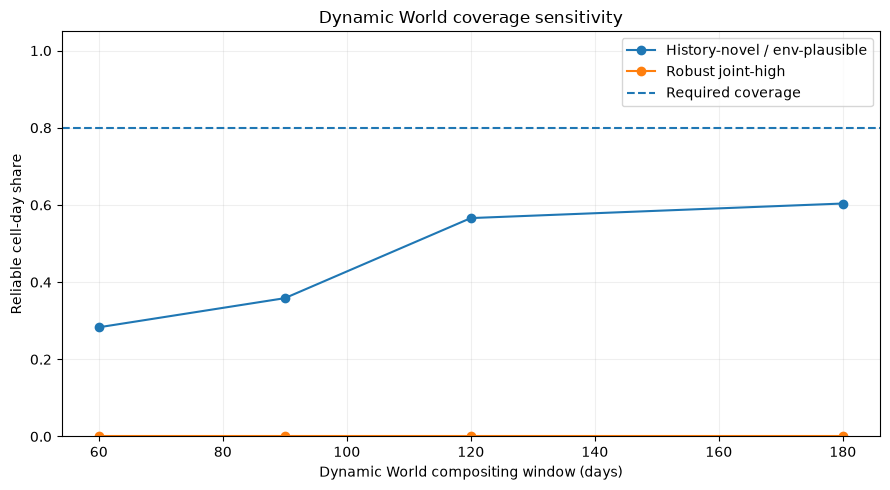

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\dynamic_world_window_sensitivity\t2\figures\01_dynamic_world_window_coverage.png


In [22]:
# 14. Coverage plot

pivot = (
    group_cell_day_coverage
    .pivot(
        index="window_days",
        columns="context_group",
        values="cell_day_reliable_share",
    )
    .sort_index()
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

for column in pivot.columns:
    ax.plot(
        pivot.index,
        pivot[column],
        marker="o",
        label=column,
    )

ax.axhline(
    MIN_GROUP_CELL_DAY_COVERAGE,
    linestyle="--",
    label="Required coverage",
)

ax.set_xlabel("Dynamic World compositing window (days)")
ax.set_ylabel("Reliable cell-day share")
ax.set_ylim(0, 1.05)
ax.set_title(
    "Dynamic World coverage sensitivity"
)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

coverage_figure = (
    FIGURE_DIR
    / "01_dynamic_world_window_coverage.png"
)

plt.savefig(
    coverage_figure,
    dpi=190,
    bbox_inches="tight",
)
plt.show()

print("Saved:", coverage_figure)

# PART E — Only if a window passes: extract full Dynamic World context

This part runs **only after** the availability-only decision has selected a window.

For the selected window, extract:
- recent mean Dynamic World probabilities;
- previous-year same-season reference probabilities;
- probability deltas;
- observation counts.

The resulting cache becomes the Dynamic World input for NB23D.

If no window passes, this section does not fabricate a cache.

In [23]:
# 15. Dynamic World feature definitions

DW_BANDS = [
    "water",
    "trees",
    "grass",
    "flooded_vegetation",
    "crops",
    "shrub_and_scrub",
    "built",
    "bare",
    "snow_and_ice",
]

In [24]:
# 16. Build full context stack for selected window

def build_full_context_stack(
    event_date,
    window,
):
    event_date = pd.Timestamp(
        event_date
    )

    recent_start = (
        event_date
        - pd.Timedelta(days=window)
    )
    recent_end = event_date

    ref_start = (
        recent_start
        - pd.DateOffset(years=1)
    )
    ref_end = (
        recent_end
        - pd.DateOffset(years=1)
    )

    recent_col = (
        ee.ImageCollection(
            "GOOGLE/DYNAMICWORLD/V1"
        )
        .filterDate(
            str(recent_start.date()),
            str(recent_end.date()),
        )
    )

    ref_col = (
        ee.ImageCollection(
            "GOOGLE/DYNAMICWORLD/V1"
        )
        .filterDate(
            str(ref_start.date()),
            str(ref_end.date()),
        )
    )

    recent_mean = (
        recent_col
        .select(DW_BANDS)
        .mean()
        .rename(
            [
                f"dw_recent_{b}"
                for b in DW_BANDS
            ]
        )
    )

    ref_mean = (
        ref_col
        .select(DW_BANDS)
        .mean()
        .rename(
            [
                f"dw_ref_{b}"
                for b in DW_BANDS
            ]
        )
    )

    delta = (
        recent_mean
        .select(
            [
                f"dw_recent_{b}"
                for b in DW_BANDS
            ]
        )
        .subtract(
            ref_mean.select(
                [
                    f"dw_ref_{b}"
                    for b in DW_BANDS
                ]
            )
        )
        .rename(
            [
                f"dw_delta_{b}"
                for b in DW_BANDS
            ]
        )
    )

    recent_count = (
        recent_col
        .select(["trees"])
        .count()
        .rename(
            ["dw_recent_valid_obs"]
        )
    )

    ref_count = (
        ref_col
        .select(["trees"])
        .count()
        .rename(
            ["dw_ref_valid_obs"]
        )
    )

    stack = (
        recent_mean
        .addBands(ref_mean)
        .addBands(delta)
        .addBands(recent_count)
        .addBands(ref_count)
    )

    return stack

In [25]:
# 17. Extract full selected-window context

selected_context = pd.DataFrame()

if SELECTED_WINDOW is None:
    print(
        "No window passed the locked coverage gate. "
        "Full Dynamic World context will NOT be extracted."
    )

else:
    selected_parts = []

    for event_date, subset in points.groupby(
        "event_date"
    ):
        event_date = pd.Timestamp(
            event_date
        )

        print(
            "Full context:",
            event_date.date(),
            "| window:",
            SELECTED_WINDOW,
            "| points:",
            len(subset),
        )

        stack = build_full_context_stack(
            event_date,
            SELECTED_WINDOW,
        )

        features = []

        for row in subset.itertuples(
            index=False
        ):
            geometry = (
                ee.Geometry.Point(
                    [
                        float(row.firms_lon),
                        float(row.firms_lat),
                    ]
                )
                .buffer(POINT_BUFFER_M)
            )

            features.append(
                ee.Feature(
                    geometry,
                    {
                        "firms_point_id": row.firms_point_id,
                        "candidate_event_id": row.candidate_event_id,
                        "context_group": row.context_group,
                        "event_date": str(
                            event_date.date()
                        ),
                    },
                )
            )

        fc = ee.FeatureCollection(
            features
        )

        reduced = stack.reduceRegions(
            collection=fc,
            reducer=ee.Reducer.mean(),
            scale=10,
            tileScale=4,
        )

        info = reduced.getInfo()

        selected_parts.append(
            pd.DataFrame(
                [
                    f.get(
                        "properties",
                        {},
                    )
                    for f in info.get(
                        "features",
                        [],
                    )
                ]
            )
        )

    selected_context = pd.concat(
        selected_parts,
        ignore_index=True,
    )

    numeric_cols = [
        c
        for c in selected_context.columns
        if (
            c.startswith("dw_recent_")
            or c.startswith("dw_ref_")
            or c.startswith("dw_delta_")
        )
    ]

    for col in numeric_cols:
        selected_context[col] = (
            pd.to_numeric(
                selected_context[col],
                errors="coerce",
            )
        )

    selected_context[
        "dw_context_reliable"
    ] = (
        selected_context[
            "dw_recent_valid_obs"
        ].ge(
            MIN_VALID_OBSERVATIONS
        )
        &
        selected_context[
            "dw_ref_valid_obs"
        ].ge(
            MIN_VALID_OBSERVATIONS
        )
    )

    selected_context[
        "dw_selected_window_days"
    ] = SELECTED_WINDOW

    print()
    print(
        "Selected-window point rows:",
        len(selected_context),
    )

    print(
        "Selected-window point reliable share:",
        round(
            selected_context[
                "dw_context_reliable"
            ].mean(),
            4,
        ),
    )

No window passed the locked coverage gate. Full Dynamic World context will NOT be extracted.


In [26]:
# 18. Save sensitivity outputs

POINT_COVERAGE_OUT = (
    EXPORT_DIR
    / "dynamic_world_point_coverage_by_window.csv"
)

CELL_DAY_OUT = (
    EXPORT_DIR
    / "dynamic_world_cell_day_reliability.csv"
)

GROUP_COVERAGE_OUT = (
    EXPORT_DIR
    / "dynamic_world_group_coverage_by_window.csv"
)

DECISION_OUT = (
    EXPORT_DIR
    / "dynamic_world_window_decision.csv"
)

METADATA_OUT = (
    EXPORT_DIR
    / "nb23d2_methodology_metadata.json"
)

coverage_points.to_csv(
    POINT_COVERAGE_OUT,
    index=False,
)

cell_day_reliability.to_csv(
    CELL_DAY_OUT,
    index=False,
)

group_cell_day_coverage.to_csv(
    GROUP_COVERAGE_OUT,
    index=False,
)

window_decision.to_csv(
    DECISION_OUT,
    index=False,
)

metadata = {
    "notebook": "23D2_dynamic_world_window_sensitivity",
    "windows_tested_days": WINDOWS,
    "point_buffer_m": POINT_BUFFER_M,
    "minimum_valid_observations_recent_and_reference": MIN_VALID_OBSERVATIONS,
    "minimum_reliable_point_share_per_cell_day": MIN_RELIABLE_POINT_SHARE_PER_CELL_DAY,
    "minimum_group_cell_day_coverage": MIN_GROUP_CELL_DAY_COVERAGE,
    "selected_window_days": SELECTED_WINDOW,
    "selection_rule": (
        "Select the shortest window for which BOTH research groups "
        "have >= 80% reliable cell-days. A cell-day is reliable if "
        ">= 50% of its exact FIRMS points have >= 3 recent and >= 3 "
        "reference Dynamic World observations."
    ),
    "selection_uses_land_cover_values": False,
}

METADATA_OUT.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved sensitivity outputs to:", EXPORT_DIR)

Saved sensitivity outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\dynamic_world_window_sensitivity\t2\exports


# PART F — Cache handoff to NB23D

Only when a window passes:

1. save the selected-window full context separately;
2. back up the existing 60-day canonical cache if present;
3. replace the canonical NB23D cache with the selected-window cache.

This means NB23D will never silently consume the failed 60-day cache after a successful
NB23D2 run.

If no window passes, the canonical cache is left unchanged and must NOT be interpreted.

In [27]:
# 19. Write selected cache only if the gate passed

if SELECTED_WINDOW is None:
    print(
        "NO PASSING WINDOW."
    )
    print(
        "Dynamic World change analysis should not be used under this design."
    )
    print(
        "No replacement cache was written."
    )

else:
    selected_context.to_csv(
        SELECTED_CACHE_PATH,
        index=False,
    )

    print(
        "Saved selected-window cache:",
        SELECTED_CACHE_PATH,
    )

    if CANONICAL_CACHE_PATH.exists():
        backup_path = (
            CACHE_DIR
            / "dynamic_world_point_context_previous_60d.csv"
        )

        if not backup_path.exists():
            shutil.copy2(
                CANONICAL_CACHE_PATH,
                backup_path,
            )

            print(
                "Backed up previous cache:",
                backup_path,
            )

    shutil.copy2(
        SELECTED_CACHE_PATH,
        CANONICAL_CACHE_PATH,
    )

    print(
        "Updated canonical NB23D cache:",
        CANONICAL_CACHE_PATH,
    )

NO PASSING WINDOW.
Dynamic World change analysis should not be used under this design.
No replacement cache was written.


In [28]:
# 20. Final decision summary

print("=== NB23D2 FINAL DECISION ===")
print()

display(
    window_decision
)

print()

if SELECTED_WINDOW is None:
    print(
        "RESULT: STOP Dynamic World change analysis."
    )
    print(
        "None of 60/90/120/180 days met the locked coverage criterion "
        "for both groups."
    )
    print(
        "Do not loosen the criterion after seeing this result."
    )
    print(
        "Next methodological step should use another contextual source "
        "or retain Dynamic World only as qualitative/non-comparative context."
    )

else:
    print(
        f"RESULT: USE {SELECTED_WINDOW}-day Dynamic World window."
    )
    print(
        "Reason: it is the SHORTEST window meeting the pre-defined "
        "coverage criterion for both groups."
    )
    print(
        "The decision did not use trees/crops/bare differences."
    )
    print()
    print(
        "Next action: rerun NB23D from its Dynamic World cache-loading cell."
    )

=== NB23D2 FINAL DECISION ===



,window_days,coverage__History-novel / env-plausible,coverage__Robust joint-high,pass__History-novel / env-plausible,pass__Robust joint-high,passes_both_groups
0,60,0.283019,0.0,False,False,False
1,90,0.358491,0.0,False,False,False
2,120,0.566038,0.0,False,False,False
3,180,0.603774,0.0,False,False,False



RESULT: STOP Dynamic World change analysis.
None of 60/90/120/180 days met the locked coverage criterion for both groups.
Do not loosen the criterion after seeing this result.
Next methodological step should use another contextual source or retain Dynamic World only as qualitative/non-comparative context.


# What to send back

After **Run All**, send this executed NB23D2 notebook.

The key outputs I will review are:

1. `point_coverage`
2. `group_cell_day_coverage`
3. `window_decision`
4. `SELECTED_WINDOW`
5. the final decision summary

### Possible outcomes

**A. A window passes**
→ rerun NB23D with the selected cache, then evaluate actual land-cover differences.

**B. No window passes**
→ stop Dynamic World comparative change analysis rather than forcing it.

This notebook is a methodological gate, not a result-selection tool.